In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

def moving_avg(temps,N=20):
    moving_avg = np.cumsum(temps)
    moving_avg[N:] -= moving_avg[:-N]
    moving_avg[N:] /= N
    moving_avg[:N] /= np.arange(1,N+1)
    return moving_avg

def PA_compliant(temps):
    if np.max(temps) > 2:
        return False
    elif np.mean(temps[-20:]) <= 1.5:
        return True
    else:
        return False

def OS_ref(temps,ref=1.5,window=1):
    stat_yrs = np.where(np.abs(df[s].to_numpy()-ref)<=0.05)[0]
    if len(stat_yrs) < 2:
        return False
    elif np.diff(stat_yrs).max()>window:
        return True
    else:
        return False 
    return 

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [3]:
df_TEs

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,1.5,3.5,6.0,3.453377,0.20,Updated lower threshold from 2C (GTPR23) to 1....
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,3.0,4.5,6.0,4.604503,0.60,Updated estimates entirely from AM22 values in...
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,NaN
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.4,9.866793,0.13,Updated upper estimate from 3C (GTPR23) to 3.4...
PERM,Boreal permafrost abrupt thaw,200,2000,1.0,1.5,2.3,13.813510,0.30,NaN
REEF,Low-latitude coral reefs,10,100,1.0,1.2,1.5,34.533774,0.00,Upper estimate reduced from 2C (AM22) to 1.5C ...
WAIS,West Antarctic ice sheet,2000,20000,0.5,1.5,3.0,5.525404,0.05,Lower estimate reduced from 1C (GTPR2023) to a...
WAM,Sahel and West African monsoon,50,500,2.0,2.8,3.5,8.633443,0.00,NaN


In [4]:
# -------- SIMULATIONS --------------
years = np.arange(1850,2301)
no_years = len(years)

# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((len(scenarios),no_years,len(df_TEs)))
p_c *= q_c

p_r = np.ones((len(scenarios),no_years,len(df_TEs)))
p_r *= q_r

for t in range(no_years):
    for i,s in enumerate(scenarios):
        p_c[i,t,:] *= temp_response(df[s].to_numpy()[t], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(df[s].to_numpy()[t], T_lim, betas))

In [5]:
D = np.zeros((len(scenarios),len_sample,len(df_TEs),no_years))
for r in tqdm.tqdm(range(len_sample)):
    for j in range(len(scenarios)):
        for t in range(1,no_years):
            D[j,r,:,t] = environmental_update(D[j,r,:,t-1],A[r],pc=p_c[j,t,:],pr=p_r[j,t,:])

# Simulating dynamics for TEs without interactions
D_noint = np.zeros((len(scenarios),len(df_TEs),no_years))
for t in tqdm.tqdm(range(1,no_years)):
    for j in range(len(scenarios)):
        D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

100%|███████████████████████████████████████| 450/450 [00:00<00:00, 3744.28it/s]


In [5]:
D.shape

(15, 500, 9, 451)

In [12]:
D_nr = np.delete(D,6,axis=2)
AR2 = k_risk(D_nr,2,axis=2)

D_nr_noint = np.delete(D_noint,6,axis=1)
AR2_noint = k_risk(D_nr_noint,2,axis=1)

In [7]:
D_nr_noint.shape

(15, 8, 451)

/tmp/ipykernel_119302/1792439239.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
/tmp/ipykernel_119302/1792439239.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')


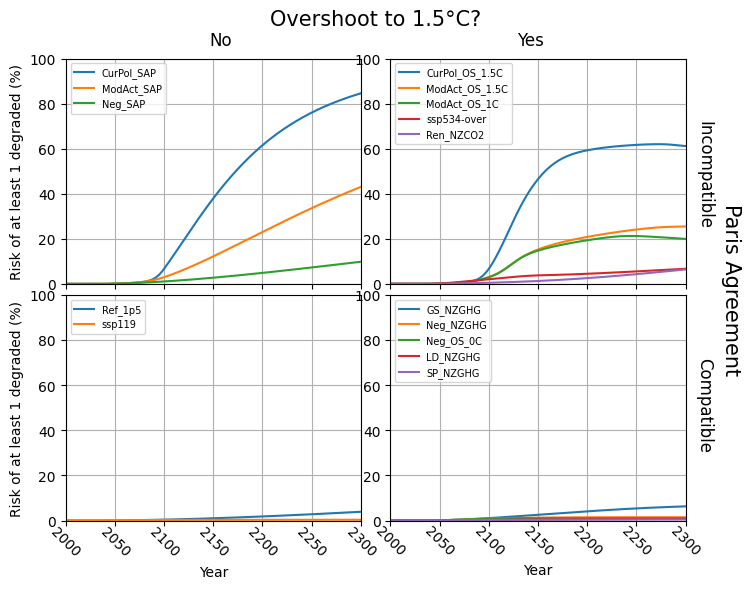

In [15]:
fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,6),sharex=True,sharey=False)
fig.subplots_adjust(wspace=0.1,hspace=0.05)
axs[0,0].set_xlim(2000,2300)
axs[0,0].set_ylim(0,100)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    to_plot = (AR2[i,:,:].mean(axis=0))*100 #-AR1_noint[i,:])*100
    axs[int(PA_compliant(moving_avg(temp))), 
        int(OS_ref(temp,ref=1.5))].plot(np.arange(1850,2301), 
                                        to_plot, label=s)
    # util.plot.ribbon_plot(axs[int(PA_compliant(moving_avg(temp))), 
    #     int(OS_ref(temp,ref=1.5))], 
    #                       years, D[i,:,:,:].sum(axis=1), axis=0, color='red',shade=[1],alpha=[0.3],label=[''])
for i in range(4):
    axs[i%2, i//2].grid()
    axs[i%2, i//2].legend(fontsize=7,loc='upper left')
for i in range(2):
    axs[1,i].set_xlabel('Year')
    axs[1,i].set_ylim([0,100])

    axs[0,i].set_ylim([0,100])
    axs[i,0].set_ylabel('Risk of at least 1 degraded (%)')

axs[1,0].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,0].tick_params(axis='x',pad=12)
axs[1,1].set_xticklabels([2000,2050,2100,2150,2200,2250,2300],rotation=-45,ha='center',va='center')
axs[1,1].tick_params(axis='x',pad=11)

ax_big = fig.add_subplot(111, frameon=False)
ax_big.tick_params(top=False, labeltop=True, bottom=False, labelbottom=False, labelsize=12, 
                   left=False, labelleft=False, right=False, labelright=True)
ax_big.set_xticks([0.25,0.75],labels=['No', 'Yes'],ha='center')
ax_big.set_yticks([0.25,0.75],labels=['Compatible', 'Incompatible'],va='center')
ax_big.tick_params(axis='y',labelrotation=-90)
# ax_big.yaxis.tick_right()
ax_big.set_ylabel('Paris Agreement',fontsize=15,rotation=-90,ha='center',va='bottom',labelpad=20)
ax_big.set_xlabel('Overshoot to 1.5°C?',fontsize=15)
ax_big.yaxis.set_label_position("right")
ax_big.xaxis.set_label_position("top")

path_out = '../../Figures/Overshoots/PROVIDE/2_risk_GTPR2025_abrupt_thaw.png'
fig.savefig(path_out,bbox_inches='tight')

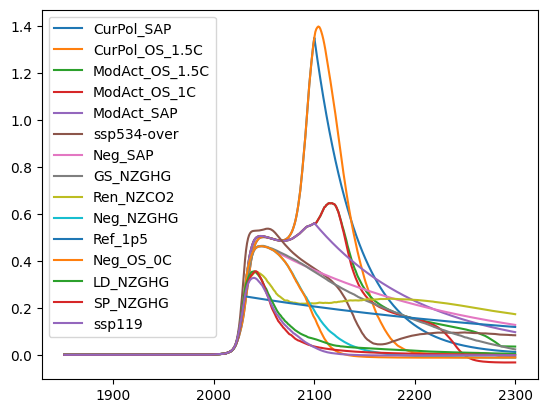

In [10]:
# fig,axs=plt.subplots(nrows=2,ncols=2,figsize=(8,8),sharex=True,sharey=False)
# plt.subplots_adjust(wspace=0.05,hspace=0.05)
# axs[0,0].set_xlim(2000,2300)
# axs[0,0].set_ylim(0,100)
for i,s in enumerate(scenarios):
    temp=df[s].to_numpy()
    to_plot = (AR1[i,:,:].mean(axis=0))*100
    plt.plot(years[1:],np.diff(to_plot),label=s)
plt.legend()
# plt.yscale('log')
# plt.ylim(0.1,100)

# plotting 2300 k-risks as a bar plot (including reefs)

In [21]:
AR_k_2300 = np.array([k_risk(D[:,:,:,-1],k,axis=2) for k in range(1,10)])

In [23]:
print(scenarios)

['CurPol_SAP' 'CurPol_OS_1.5C' 'ModAct_OS_1.5C' 'ModAct_OS_1C'
 'ModAct_SAP' 'ssp534-over' 'Neg_SAP' 'GS_NZGHG' 'Ren_NZCO2' 'Neg_NZGHG'
 'Ref_1p5' 'Neg_OS_0C' 'LD_NZGHG' 'SP_NZGHG' 'ssp119']


(-1.1400000000000001, 15.14)

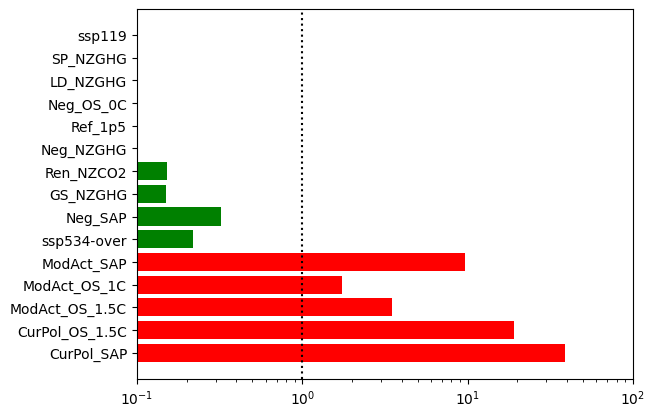

In [52]:
fig,ax=plt.subplots()
# ax.bar(np.arange(1,10),AR_k_2300[:,1,:].mean(axis=-1)*100)

k = 4 # minimum number of degraded elements
to_plot = AR_k_2300[k-1,:,:].mean(axis=-1)*100
mask_g = to_plot<=1
mask_r = to_plot>1
ax.barh(scenarios[mask_r],to_plot[mask_r],color='red')
ax.barh(scenarios[mask_g],to_plot[mask_g],color='green') 
ax.set_xscale('log')
ax.set_xlim(1e-1,1e2)
ylim = ax.get_ylim()
ax.plot([1]*2,ylim,c='k',ls=':')
ax.set_ylim(ylim)
# ax.set_ylabel(r"Risk of at least $k$ degraded elements")
# ax.set_xlabel(r"$k$")

In [81]:
D.shape

(15, 500, 9, 451)

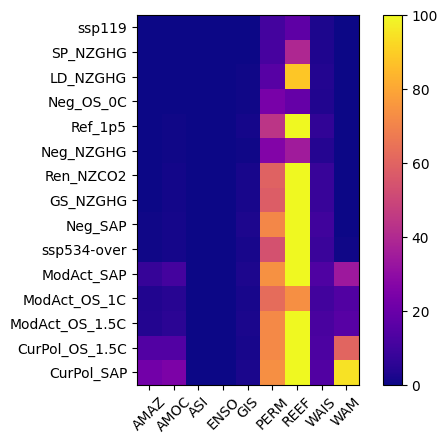

In [84]:
fig,ax=plt.subplots()
# ax.bar(np.arange(1,10),AR_k_2300[:,1,:].mean(axis=-1)*100)

to_plot = D.mean(axis=1)[:,:,-1].T*100 #AR_k_2300.mean(axis=-1)*100
im=ax.imshow(to_plot.T,vmin=0,vmax=100,cmap='plasma')
ax.invert_yaxis()
cb=fig.colorbar(im)
ax.set_yticks(np.arange(15),scenarios);
# ax.set_xticks(np.arange(9),np.arange(9)+1);
ax.set_xticks(np.arange(9),df_TEs.index.values,rotation=45);